# Persiapan Data: membangun ulang bundle training dari dataset asli
Mengikuti manifest di `manifest/` (daftar pasti train/val/test).
Folder dataset mentah (unduh dan ekstrak ke satu folder induk):
| Folder | Dataset |
|---|---|
| `archive (1)/PlantVillage/` | PlantVillage (Kaggle emmarex/plantdisease) |
| `archive (2)/leaves_healthy_or_diseased/` | Leaves healthy or diseased (Kaggle) |
| `archive/rice_leaf_diseases/` | Rice leaf diseases (Kaggle) |
| `archive (3)/PlantDoc/` | PlantDoc (datasetninja) |
| `archive (4)/inaturalist/`, `archive (5)/inat_jenis/` | iNaturalist (CC; atribusi di manifest/atribusi_inaturalist.csv) |

## Bagian 1: Konfigurasi path dan membaca manifest

In [1]:
from pathlib import Path
import pandas as pd

# --- Konfigurasi path (ubah di sini kalau dataset ada di lokasi lain) ---
SUMBER = Path(r"E:\Project CNN AIT")   # folder induk berisi archive*
MANIFEST = Path("manifest")              # relatif terhadap folder training/
OUT = Path(r"E:\klorofil_data")         # keluaran, di luar repo

OUT.mkdir(parents=True, exist_ok=True)

df_k = pd.read_csv(MANIFEST / "data_kesehatan.csv")
df_j = pd.read_csv(MANIFEST / "data_jenis.csv")

print(f"df_k: {len(df_k):,} baris")
print(f"df_j: {len(df_j):,} baris")
print()
print(df_k.groupby(["split", "source"]).size())

df_k: 44,739 baris
df_j: 12,746 baris

split  source      
test   inat             1536
       leaves            676
       plantdoc          385
       plantvillage     3093
       rice               18
train  bgaug            6690
       inat             7165
       leaves           3152
       plantdoc         1796
       plantvillage    14436
       rice               84
val    inat             1536
       leaves            674
       plantdoc          385
       plantvillage     3095
       rice               18
dtype: int64


## Bagian 2: Memastikan semua file asal ada

In [ ]:
# Baris bgaug merujuk ke gambar train hasil olahan, bukan file di SUMBER
asal_k = df_k.loc[df_k["source"] != "bgaug", "asal"]
semua_asal = pd.concat([asal_k, df_j["asal"]]).unique()

hilang = [a for a in semua_asal if not (SUMBER / a).exists()]

print(f"Dicek : {len(semua_asal):,} file unik")
print(f"Hilang: {len(hilang):,} file")
if hilang:
    print("Contoh yang hilang:")
    for a in hilang[:5]:
        print("  ", a)

assert len(hilang) == 0, "Ada file asal yang hilang, periksa SUMBER"

Dicek : 41,688 file unik
Hilang: 0 file


## Bagian 3: Fungsi memuat gambar

In [ ]:
from PIL import Image

def muat_gambar(path, size=128):
    """Buka gambar -> RGB -> crop persegi tengah -> resize size x size (sama dengan pipeline lama)."""
    with Image.open(path) as im:
        # draft: decoder JPEG membaca versi kecil dari foto besar (lebih cepat, identik dengan pipeline lama)
        im.draft("RGB", (size * 2, size * 2))
        im = im.convert("RGB")
    w, h = im.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    im = im.crop((left, top, left + s, top + s))
    return im.resize((size, size), Image.Resampling.LANCZOS)

# Uji: satu gambar dari setiap sumber (kecuali bgaug, yang belum ada di SUMBER)
contoh = df_k[df_k["source"] != "bgaug"].groupby("source").head(1)
for _, r in contoh.iterrows():
    g = muat_gambar(SUMBER / r["asal"])
    print(f"{r['source']:<13} {g.size} {g.mode}")
    assert g.size == (128, 128) and g.mode == "RGB"

plantvillage  (128, 128) RGB
leaves        (128, 128) RGB
rice          (128, 128) RGB
plantdoc      (128, 128) RGB
inat          (128, 128) RGB


## Bagian 4: Membangun data kesehatan (38.049 gambar)

In [ ]:
import time

df_k_asli = df_k[df_k["source"] != "bgaug"]
OUT_K = OUT / "kesehatan"

t0 = time.time()
diproses = dilewati = 0
for i, r in enumerate(df_k_asli.itertuples(index=False), 1):
    dst = OUT_K / r.file
    if dst.exists():
        dilewati += 1
    else:
        dst.parent.mkdir(parents=True, exist_ok=True)
        muat_gambar(SUMBER / r.asal).save(dst, "JPEG", quality=95)
        diproses += 1
    if i % 2000 == 0:
        print(f"  {i:,}/{len(df_k_asli):,}  ({time.time() - t0:.0f} dtk)")

print(f"Diproses: {diproses:,} | Dilewati (sudah ada): {dilewati:,} | Total: {len(df_k_asli):,}")
print(f"Lama: {(time.time() - t0) / 60:.1f} menit")

  2,000/38,049  (86 dtk)
  4,000/38,049  (169 dtk)
  6,000/38,049  (251 dtk)
  8,000/38,049  (330 dtk)
  10,000/38,049  (410 dtk)
  12,000/38,049  (488 dtk)
  14,000/38,049  (567 dtk)
  16,000/38,049  (647 dtk)
  18,000/38,049  (725 dtk)
  20,000/38,049  (799 dtk)
  22,000/38,049  (990 dtk)
  24,000/38,049  (1238 dtk)
  26,000/38,049  (1433 dtk)
  28,000/38,049  (1557 dtk)
  30,000/38,049  (1645 dtk)
  32,000/38,049  (1734 dtk)
  34,000/38,049  (1820 dtk)
  36,000/38,049  (1904 dtk)
  38,000/38,049  (1990 dtk)
Diproses: 38,049 | Dilewati (sudah ada): 0 | Total: 38,049
Lama: 33.2 menit


Verifikasi: bandingkan 200 gambar acak dengan data olahan lama di `SUMBER/data/processed/`.

In [ ]:
import numpy as np

LAMA = SUMBER / "data" / "processed"
sampel = df_k_asli.sample(200, random_state=42)

selisih_maks = 0
for f in sampel["file"]:
    baru = np.asarray(Image.open(OUT_K / f), dtype=np.int16)
    lama = np.asarray(Image.open(LAMA / f), dtype=np.int16)
    selisih_maks = max(selisih_maks, int(np.abs(baru - lama).max()))

print(f"Selisih piksel maksimum (200 sampel): {selisih_maks}")
assert selisih_maks == 0, "Hasil bangun ulang berbeda dari data lama"

Selisih piksel maksimum (200 sampel): 0


## Bagian 5: Augmentasi ganti latar (6.690 gambar train)
### 5a: Segmentasi, memisahkan daun dari latar

In [ ]:
import cv2

KERNEL = np.ones((3, 3), np.uint8)

def masker_daun(bgr):
    """Masker daun 0/1 dari foto berlatar polos, atau None kalau meragukan."""
    hsv = cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    bukan_biru = (h < 90) | (h > 150)          # latar leaves abu-kebiruan
    m = ((s > 45) & (v > 40) & bukan_biru).astype(np.uint8)

    # buang bintik kecil, tutup celah, lalu kikis pinggiran sisa latar
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, KERNEL)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, KERNEL)
    m = cv2.erode(m, KERNEL, iterations=1)

    # ambil komponen terbesar saja (daunnya)
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    if n < 2:
        return None
    terbesar = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    m = (lab == terbesar).astype(np.uint8)

    # isi lubang: flood fill latar dari pojok (dengan bingkai 1 px),
    # piksel yang tidak terjangkau = daun atau lubang di dalam daun
    pad = np.pad(m, 1)
    cv2.floodFill(pad, None, (0, 0), 2)
    m = (pad[1:-1, 1:-1] != 2).astype(np.uint8)

    luas = m.mean()
    if luas < 0.08 or luas > 0.92:
        return None
    return m

df_bg = df_k[df_k["source"] == "bgaug"]
assert len(df_bg) == 6690, len(df_bg)
print(f"df_bg: {len(df_bg):,} baris")

df_bg: 6,690 baris


Uji pada 8 gambar sumber: baris atas gambar asli, baris bawah maskernya (judul = luas daun).

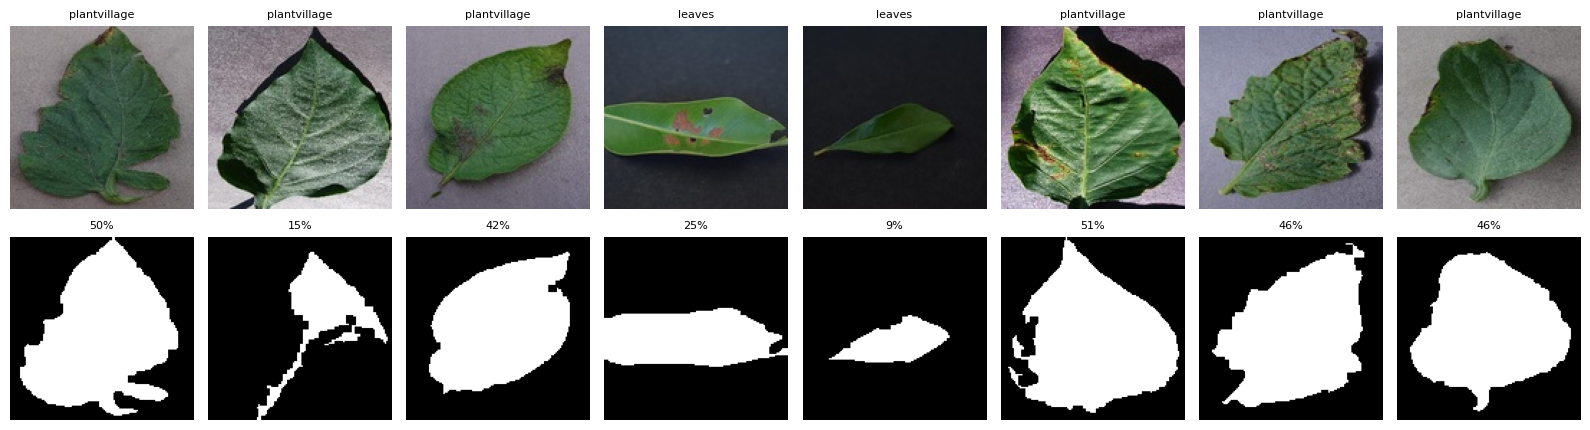

In [ ]:
import matplotlib.pyplot as plt

uji = df_bg.sample(8, random_state=0)
fig, ax = plt.subplots(2, 8, figsize=(16, 4.5))
for j, a in enumerate(uji["asal"]):
    bgr = cv2.imread(str(OUT_K / a))
    m = masker_daun(bgr)
    ax[0, j].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    ax[1, j].imshow(m if m is not None else np.zeros(bgr.shape[:2]), cmap="gray", vmin=0, vmax=1)
    ax[0, j].set_title(Path(a).name.split("__")[0], fontsize=8)
    ax[1, j].set_title("None" if m is None else f"{m.mean():.0%}", fontsize=8)
for a_ in ax.flat:
    a_.axis("off")
plt.tight_layout()
plt.show()

Hitung gambar sumber yang maskernya ditolak (None).

In [ ]:
t0 = time.time()
gagal = [a for a in df_bg["asal"] if masker_daun(cv2.imread(str(OUT_K / a))) is None]
print(f"Masker None: {len(gagal)} dari {len(df_bg):,}  ({time.time() - t0:.0f} dtk)")
for a in gagal[:5]:
    print("  ", a)

Masker None: 0 dari 6,690  (10 dtk)


**Keterbatasan segmentasi HSV.** Masker dibuat dari saturasi, jadi bagian daun yang pucat atau keputihan (saturasi rendah) ikut terbuang. Contohnya gambar ke-2 di atas: luas maskernya hanya 15%. Dari 6.690 gambar sumber, 681 punya luas daun < 15%, sehingga sebagian di antaranya hanya potongan daun yang ditempel ke latar baru. Data lama juga begitu karena algoritmanya sama (sudah dicek: 0 masker berbeda dengan `leaf_mask` dari skrip lama). Tepi masker yang bergerigi wajar karena resolusinya hanya 128 px.

### 5b: Tempel daun ke latar baru

In [ ]:
import random

HIJAU = [(34, 85, 34), (60, 110, 50), (30, 60, 25), (90, 140, 70), (70, 90, 60),
         (100, 80, 50), (60, 50, 40), (140, 150, 120), (40, 70, 70)]   # BGR
S = 128

# Pool latar: foto lapangan train (plantdoc/inat) hasil Bagian 4
pool = [OUT_K / f for f in df_k.loc[(df_k["split"] == "train")
                                    & df_k["source"].isin(["plantdoc", "inat"]), "file"]]
print(f"pool latar: {len(pool):,} gambar")

def latar(rng, pool):
    """Latar 128x128 float32: 70% potongan foto lapangan yang di-blur, 30% gradien + noise."""
    if rng.random() < 0.7:
        img = cv2.imread(str(rng.choice(pool)))
        c = rng.randint(S // 3, S)
        x, y = rng.randint(0, S - c), rng.randint(0, S - c)
        img = cv2.resize(img[y:y + c, x:x + c], (S, S), interpolation=cv2.INTER_LINEAR)
        k = rng.choice((11, 17, 25, 35))
        bg = cv2.GaussianBlur(img, (k, k), 0).astype(np.float32)
    else:
        c1 = np.array(rng.choice(HIJAU), np.float32)
        c2 = np.array(rng.choice(HIJAU), np.float32)
        t = np.linspace(0, 1, S, dtype=np.float32)
        t = t[None, :, None] if rng.random() < 0.5 else t[:, None, None]   # horizontal / vertikal
        bg = (1 - t) * c1 + t * c2 + np.zeros((S, S, 3), np.float32)
        noise = np.random.RandomState(rng.randint(0, 2**31)).normal(0, 12, (S, S, 3))
        bg = np.clip(bg + noise, 0, 255).astype(np.uint8)
        bg = cv2.GaussianBlur(bg, (9, 9), 0).astype(np.float32)
    return np.clip(bg * rng.uniform(0.7, 1.2), 0, 255).astype(np.float32)

def tempel(fg, mask, bg, rng):
    """Tempel daun (fg, BGR uint8) bermasker ke latar bg (float32) dengan alpha blending."""
    n = max(8, int(S * rng.uniform(0.6, 1.0)))
    fg = cv2.resize(fg, (n, n))                        # bilinear, sama dengan skrip lama
    m = cv2.resize(mask.astype(np.float32), (n, n))    # masker float -> tepi halus
    if rng.random() < 0.5:
        fg, m = fg[:, ::-1], m[:, ::-1]
    a = cv2.GaussianBlur(m.astype(np.float32), (3, 3), 0)[..., None]   # tepi halus, 0..1
    x, y = rng.randint(0, S - n), rng.randint(0, S - n)
    out = bg.copy()
    out[y:y + n, x:x + n] = a * fg.astype(np.float32) + (1 - a) * out[y:y + n, x:x + n]
    return np.clip(out, 0, 255).astype(np.uint8)

pool latar: 8,961 gambar


Pratinjau 8 hasil tempelan dari 8 gambar uji yang sama seperti di 5a.

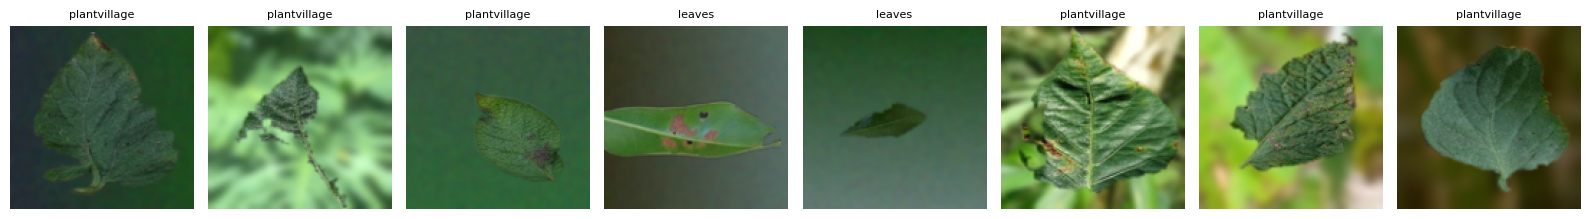

In [ ]:
# Pratinjau (tidak menulis file). rng terpisah supaya tidak mengganggu proses penuh.
rng_uji = random.Random(0)
fig, ax = plt.subplots(1, 8, figsize=(16, 2.6))
for j, a in enumerate(uji["asal"]):
    bgr = cv2.imread(str(OUT_K / a))
    hasil = tempel(bgr, masker_daun(bgr), latar(rng_uji, pool), rng_uji)
    ax[j].imshow(cv2.cvtColor(hasil, cv2.COLOR_BGR2RGB))
    ax[j].set_title(Path(a).name.split("__")[0], fontsize=8)
    ax[j].axis("off")
plt.tight_layout()
plt.show()

Proses penuh: tulis 6.690 gambar bgaug ke `OUT_K`.

In [ ]:
# Proses penuh: selalu timpa (tanpa lewati-kalau-sudah-ada) supaya urutan angka acak tetap
rng = random.Random(42)

harap = "train/" + df_bg["label"] + "/bgaug__" + df_bg["asal"].map(lambda a: Path(a).name)
assert (df_bg["file"] == harap).all(), "file bgaug tidak cocok dengan label/asal"

t0 = time.time()
for i, r in enumerate(df_bg.itertuples(index=False), 1):
    bgr = cv2.imread(str(OUT_K / r.asal))
    m = masker_daun(bgr)
    assert m is not None, r.asal
    hasil = tempel(bgr, m, latar(rng, pool), rng)
    cv2.imwrite(str(OUT_K / r.file), hasil, [cv2.IMWRITE_JPEG_QUALITY, 95])
    if i % 1000 == 0:
        print(f"  {i:,}/{len(df_bg):,}  ({time.time() - t0:.0f} dtk)")
print(f"Lama: {(time.time() - t0) / 60:.1f} menit")

n_bgaug = len(list((OUT_K / "train").rglob("bgaug__*.jpg")))
n_train = len(list((OUT_K / "train").rglob("*.jpg")))
print(f"bgaug di disk: {n_bgaug:,} | train total: {n_train:,}")
assert n_bgaug == 6690 and n_train == 33323

  1,000/6,690  (25 dtk)
  2,000/6,690  (50 dtk)
  3,000/6,690  (74 dtk)
  4,000/6,690  (97 dtk)
  5,000/6,690  (120 dtk)
  6,000/6,690  (142 dtk)
Lama: 2.6 menit
bgaug di disk: 6,690 | train total: 33,323


**Catatan reproduksi.** Daftar gambar sumber bgaug sama persis dengan data lama (diambil dari manifest), tetapi hasil tempelannya tidak identik byte per byte: urutan pemakaian `rng` di skrip lama berbeda, sehingga latar, skala, flip, dan posisinya lain. Ini tidak masalah karena augmentasi hanya ada di split train; val dan test tetap identik dengan data lama.

## Bagian 6: Data jenis (12.746 gambar)
9.107 gambar (plantvillage, inat, plantdoc, leaves, rice) disalin dari hasil Bagian 4 lewat kolom kunci `asal`; 3.639 gambar `inatj` diproses dari nol dengan `muat_gambar`.

In [14]:
import shutil

OUT_J = OUT / "jenis"

assert (df_j["source"] != "bgaug").all(), "df_j tidak boleh berisi bgaug"
assert len(df_j) == 12746, len(df_j)

per_split = df_j["split"].value_counts()
print(per_split.to_string())
assert per_split.to_dict() == {"train": 8929, "val": 1893, "test": 1924}

# asal -> file kesehatan (dari baris non-bgaug saja)
peta = dict(zip(df_k_asli["asal"], df_k_asli["file"]))

df_j_salin = df_j[df_j["source"] != "inatj"]
df_j_inatj = df_j[df_j["source"] == "inatj"]

print(
    f"disalin dari kesehatan: {len(df_j_salin):,} | "
    f"inatj diproses: {len(df_j_inatj):,}"
)

assert df_j_salin["asal"].isin(peta).all(), (
    "ada asal jenis yang tidak ada di manifest kesehatan"
)


split
train    8929
test     1924
val      1893
disalin dari kesehatan: 9,107 | inatj diproses: 3,639


Bangun data jenis: salin, proses inatj, lalu cek jumlah per split.

In [15]:
# 1) Salin 9.107 gambar dari hasil Bagian 4 (folder label berbeda: sakit/sehat -> jenis tanaman)
t0 = time.time()
for r in df_j_salin.itertuples(index=False):
    dst = OUT_J / r.file
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(OUT_K / peta[r.asal], dst)
print(f"Disalin: {len(df_j_salin):,}  ({time.time() - t0:.0f} dtk)")

# 2) Proses 3.639 gambar inatj dari nol (tanpa unsur acak, jadi boleh dilewati kalau sudah ada)
t0 = time.time()
diproses = dilewati = 0
for r in df_j_inatj.itertuples(index=False):
    dst = OUT_J / r.file
    if dst.exists():
        dilewati += 1
        continue
    dst.parent.mkdir(parents=True, exist_ok=True)
    muat_gambar(SUMBER / r.asal).save(dst, "JPEG", quality=95)
    diproses += 1
print(f"inatj diproses: {diproses:,} | dilewati: {dilewati:,}  ({time.time() - t0:.0f} dtk)")

# 3) Cek jumlah di disk
for split, harap in {"train": 8929, "val": 1893, "test": 1924}.items():
    n = len(list((OUT_J / split).rglob("*.jpg")))
    print(f"{split:<6} {n:,}")
    assert n == harap, (split, n, harap)
assert not list(OUT_J.rglob("bgaug__*")), "tidak boleh ada bgaug di data jenis"

Disalin: 9,107  (295 dtk)
inatj diproses: 3,639 | dilewati: 0  (167 dtk)
train  8,929
val    1,893
test   1,924


Verifikasi: bandingkan 200 gambar acak dengan data jenis lama di `SUMBER/data/jenis/`.

In [16]:
LAMA_J = SUMBER / "data" / "jenis"
sampel_j = df_j.sample(200, random_state=42)

selisih_maks = 0
for f in sampel_j["file"]:
    baru = np.asarray(Image.open(OUT_J / f), dtype=np.int16)
    lama = np.asarray(Image.open(LAMA_J / f), dtype=np.int16)
    selisih_maks = max(selisih_maks, int(np.abs(baru - lama).max()))

print(sampel_j["source"].value_counts().to_string())
print(f"Selisih piksel maksimum (200 sampel): {selisih_maks}")
assert selisih_maks == 0, "Data jenis hasil bangun ulang berbeda dari data lama"

source
plantvillage    63
inatj           58
inat            37
plantdoc        30
leaves          10
rice             2
Selisih piksel maksimum (200 sampel): 0


## Bagian 7: Zip bundle
Struktur isi zip sama dengan yang dibaca notebook Colab: `data/processed/...` untuk kesehatan dan `data/jenis/...` untuk jenis, masing-masing dengan `split.csv` (kolom `file, split, label, source`).

In [17]:
import zipfile

def buat_zip(df, folder, prefix, tujuan):
    """Zip gambar di folder sesuai manifest df, dengan nama arsip prefix/file, plus prefix/split.csv."""
    t0 = time.time()
    with zipfile.ZipFile(tujuan, "w", zipfile.ZIP_STORED) as z:   # JPEG sudah terkompresi
        for f in df["file"]:
            z.write(folder / f, arcname=f"{prefix}/{f}")
        z.writestr(f"{prefix}/split.csv",
                   df[["file", "split", "label", "source"]].to_csv(index=False))
    print(f"{tujuan.name}: {len(df):,} gambar  ({time.time() - t0:.0f} dtk)")

ZIP_K = OUT / "colab_bundle.zip"
ZIP_J = OUT / "jenis_bundle.zip"
buat_zip(df_k, OUT_K, "data/processed", ZIP_K)
buat_zip(df_j, OUT_J, "data/jenis", ZIP_J)

colab_bundle.zip: 44,739 gambar  (947 dtk)
jenis_bundle.zip: 12,746 gambar  (285 dtk)


Verifikasi isi kedua zip.

In [18]:
# Verifikasi: buka ulang tiap zip
for tujuan, prefix, harap in [(ZIP_K, "data/processed", 44739), (ZIP_J, "data/jenis", 12746)]:
    with zipfile.ZipFile(tujuan) as z:
        nama = z.namelist()
    n_jpg = sum(n.endswith(".jpg") for n in nama)
    ada_csv = f"{prefix}/split.csv" in nama
    print(f"{tujuan.name:<18} {n_jpg:>6,} jpg | split.csv: {ada_csv} | {tujuan.stat().st_size / 1e6:,.0f} MB")
    assert n_jpg == harap and ada_csv, tujuan

colab_bundle.zip   44,739 jpg | split.csv: True | 412 MB
jenis_bundle.zip   12,746 jpg | split.csv: True | 144 MB


## Ringkasan

Notebook ini membangun ulang kedua bundle training dari dataset asli, mengikuti manifest di `manifest/`.

**Sumber dataset** (di `SUMBER = E:\Project CNN AIT`): PlantVillage, Leaves healthy or diseased, Rice leaf diseases, PlantDoc, dan iNaturalist (`inat` untuk kesehatan, `inatj` khusus jenis). Rincian folder ada di sel paling atas; atribusi iNaturalist di `manifest/atribusi_inaturalist.csv`.

| Bagian | Isi | Jumlah |
|---|---|---|
| 1 | Baca manifest | `df_k` 44.739, `df_j` 12.746 |
| 2 | Cek file asal ada | 41.688 file unik, 0 hilang |
| 3 | `muat_gambar`: `draft` → RGB → crop persegi tengah → 128×128 LANCZOS | – |
| 4 | Data kesehatan non-bgaug | 38.049 gambar |
| 5 | Augmentasi ganti latar (train) | 6.690 gambar, train total 33.323 |
| 6 | Data jenis | 9.107 disalin + 3.639 inatj = 12.746 |
| 7 | Zip bundle | `colab_bundle.zip` 44.739, `jenis_bundle.zip` 12.746 |

**Hasil verifikasi**
- Kesehatan non-bgaug (Bagian 4) dan jenis (Bagian 6, termasuk inatj): 200 sampel acak, selisih piksel maksimum **0** terhadap data lama, jadi identik.
- Masker segmentasi (5a): 0 berbeda dari `leaf_mask` skrip lama, 0 masker ditolak.
- bgaug (5b): daftar gambar sumbernya sama dengan data lama, tetapi hasil tempelannya **tidak identik byte per byte** karena urutan pemakaian `rng` berbeda. Ini hanya memengaruhi train; val dan test identik.
- `predictor.py` tidak memakai `draft`. Untuk foto JPEG besar (lebih dari 256 px), piksel hasil `muat_gambar` bisa sedikit berbeda dari input web app. Efeknya ke prediksi belum diukur. Sebagai pembanding, perbedaan decoder JPEG TF vs PIL di proyek referensi mengubah sekitar 0,4% label.

**Cara pakai**
1. Upload `E:\klorofil_data\colab_bundle.zip` dan `E:\klorofil_data\jenis_bundle.zip` ke `MyDrive/`.
2. Jalankan `training_kesehatan.ipynb` (membaca `data/processed/`) dan `training_jenis.ipynb` (membaca `data/jenis/`) di Colab tanpa perubahan. Langkah hapus `bgaug__*` di `training_jenis` akan menghapus 0 file, dan assert-nya tetap lolos.